In [ ]:
import pandas as pd
import numpy as np
from scipy.stats.mstats import winsorize
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_all_phones.csv to cleaned_all_phones.csv


In [ ]:
df = pd.read_csv('cleaned_all_phones.csv')
df.head()

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,video_1080p,video_4K,video_8K,video_30fps,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD)
0,Y6II Compact,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,...,False,False,False,True,False,False,False,False,False,120.0
1,K20 plus,LG,Android 7.0,5.3,720x1280,2700,Li-Ion,2,2016-12-01,140.0,...,True,False,False,True,False,False,False,False,False,100.0
2,P8 Lite (2017),Huawei,Android 7.0,5.2,1080x1920,3000,Li-Ion,4,2017-01-01,147.0,...,True,False,False,True,False,False,False,False,False,420.0
3,Redmi Note 4,Xiaomi,Android 6.0,5.5,1080x1920,4100,Li-Po,4,2017-01-01,165.0,...,True,False,False,True,False,True,False,False,False,150.0
4,P10,Huawei,Android 7.0,5.1,1080x1920,3200,Li-Ion,4,2017-02-01,145.0,...,True,True,False,True,True,False,False,False,False,420.0


#Xóa một số thiết bị có thông số đặc biệt

In [ ]:
df = df[~(
    (df['inches'] >= 9) |
    (df['storage(GB)'] <= 4) |
    (df['weight(g)'] >= 350)
)]
df.drop(df[df['os'] == 'Tizen 3.0'].index, inplace=True)

# Tạo mới đặc trưng (kết hợp các đặc trưng cũ, đặc trưng lấy từ nguồn bên ngoài)

In [ ]:
#Tách 'resolution' thành hai cột 'width' và 'height'
df[['width', 'height']] = df['resolution'].str.lower().str.strip().str.split('x', expand=True).astype(int)

In [ ]:
# Chuyển 'announcement_date' về dạng datetime
df['announcement_date'] = pd.to_datetime(df['announcement_date'], errors='coerce')

# Tạo cột 'announcement_year'
df['announcement_year'] = df['announcement_date'].dt.year

In [ ]:
#Tạo thêm 1 cột tổng các chức năng camera
total_cam_func = [ i for i in df.columns if 'video' in i]
df['total_cam_func'] = df[total_cam_func].sum(axis=1)

In [ ]:
#Tạo biến tổng hợp theo nhóm biến 'brand' theo theo giá trung bình
brand_price_mean = df.groupby('brand')['price(USD)'].mean()
df['brand_group'] = df['brand'].map(brand_price_mean)

In [ ]:
#Tạo biến ppi: pixel per inch
df['ppi'] = ((df['width']**2 + df['height']**2)**0.5) / df['inches']

In [ ]:
df.head()

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,video_240fps,video_480fps,video_960fps,price(USD),width,height,announcement_year,total_cam_func,brand_group,ppi
0,Y6II Compact,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,...,False,False,False,120.0,720,1280,2016,2,403.913650,293.720956
1,K20 plus,LG,Android 7.0,5.3,720x1280,2700,Li-Ion,2,2016-12-01,140.0,...,False,False,False,100.0,720,1280,2016,2,264.000000,277.095242
2,P8 Lite (2017),Huawei,Android 7.0,5.2,1080x1920,3000,Li-Ion,4,2017-01-01,147.0,...,False,False,False,420.0,1080,1920,2017,2,403.913650,423.635994
3,Redmi Note 4,Xiaomi,Android 6.0,5.5,1080x1920,4100,Li-Po,4,2017-01-01,165.0,...,False,False,False,150.0,1080,1920,2017,4,306.254129,400.528576
4,P10,Huawei,Android 7.0,5.1,1080x1920,3200,Li-Ion,4,2017-02-01,145.0,...,False,False,False,420.0,1080,1920,2017,5,403.913650,431.942582


# Chọn encoding phù hợp (One-hot encoding, Label encoding,...) -> Label encoding

In [ ]:
# Label 'os' theo thế hệ old, mid, new
def categorize_os(os):
    os = str(os).lower()
    if any(v in os for v in ['android 5', 'android 6', 'android 7', 'android 8','ios 11',  'emui 12']):
        return 'old'
    elif any(v in os for v in ['android 9', 'android 10', 'android 11', 'ios 12', 'ios 13', 'ios 14', 'emui 13']):
        return 'mid'
    elif any(v in os for v in ['android 12', 'android 13', 'ios 15', 'ios 16']):
        return 'new'
    else:
        return 'unknown'

df['os_group'] = df['os'].apply(categorize_os)

In [ ]:
# Chuyển 'os_group' thành dạng số
os_group_mapping = {'old': 0, 'mid': 1, 'new': 2, 'unknown': -1}
df['os_group_encoded'] = df['os_group'].map(os_group_mapping)
df.drop(['os', 'os_group'], axis=1, inplace=True)

In [ ]:
# One-hot biến 'battery_type'
battery_mapping = {'Li-Po': 0, 'Li-Ion': 1}
df['battery_type_encoded'] = df['battery_type'].map(battery_mapping)
df.drop('battery_type', axis=1, inplace=True)

In [ ]:
# One-hot biến 'brand'
df = pd.get_dummies(df, columns=['brand'], dtype=int)

In [ ]:
# Chuyển các biến bool thành dạng 0/1
video_cols = [
    'video_720p', 'video_1080p', 'video_4K', 'video_8K',
    'video_30fps', 'video_60fps', 'video_120fps',
    'video_240fps', 'video_480fps', 'video_960fps'
]

df[video_cols] = df[video_cols].astype(int)

In [ ]:
df.head()

,phone_name,inches,resolution,battery,ram(GB),announcement_date,weight(g),storage(GB),video_720p,video_1080p,...,brand_Huawei,brand_LG,brand_Lenovo,brand_OnePlus,brand_Oppo,brand_Realme,brand_Samsung,brand_Sony,brand_Vivo,brand_Xiaomi
0,Y6II Compact,5.0,720x1280,2200,2,2016-09-01,140.0,16,1,0,...,1,0,0,0,0,0,0,0,0,0
1,K20 plus,5.3,720x1280,2700,2,2016-12-01,140.0,16,0,1,...,0,1,0,0,0,0,0,0,0,0
2,P8 Lite (2017),5.2,1080x1920,3000,4,2017-01-01,147.0,16,0,1,...,1,0,0,0,0,0,0,0,0,0
3,Redmi Note 4,5.5,1080x1920,4100,4,2017-01-01,165.0,32,1,1,...,0,0,0,0,0,0,0,0,0,1
4,P10,5.1,1080x1920,3200,4,2017-02-01,145.0,32,1,1,...,1,0,0,0,0,0,0,0,0,0


# Loại bỏ những đặc trưng nào không có nhiều giá trị dự đoán (ví dụ: biến dạng định danh, biến chỉ nhận 1 giá trị)

In [ ]:
# Xóa 3 biến 'phone_name', 'resolution', 'announcement_date'
df.drop(['phone_name', 'resolution', 'announcement_date'], axis=1, inplace=True)

In [ ]:
df.head()

,inches,battery,ram(GB),weight(g),storage(GB),video_720p,video_1080p,video_4K,video_8K,video_30fps,...,brand_Huawei,brand_LG,brand_Lenovo,brand_OnePlus,brand_Oppo,brand_Realme,brand_Samsung,brand_Sony,brand_Vivo,brand_Xiaomi
0,5.0,2200,2,140.0,16,1,0,0,0,1,...,1,0,0,0,0,0,0,0,0,0
1,5.3,2700,2,140.0,16,0,1,0,0,1,...,0,1,0,0,0,0,0,0,0,0
2,5.2,3000,4,147.0,16,0,1,0,0,1,...,1,0,0,0,0,0,0,0,0,0
3,5.5,4100,4,165.0,32,1,1,0,0,1,...,0,0,0,0,0,0,0,0,0,1
4,5.1,3200,4,145.0,32,1,1,1,0,1,...,1,0,0,0,0,0,0,0,0,0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x = df['price(USD)']

df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

# Bây giờ df_scaled là dữ liệu đã chuẩn hóa
df_scaled.head()

,inches,battery,ram(GB),weight(g),storage(GB),video_720p,video_1080p,video_4K,video_8K,video_30fps,...,brand_Huawei,brand_LG,brand_Lenovo,brand_OnePlus,brand_Oppo,brand_Realme,brand_Samsung,brand_Sony,brand_Vivo,brand_Xiaomi
0,-3.250742,-2.824744,-1.762905,-2.148532,-1.255623,0.921355,-13.679364,-1.065247,-0.246183,0.348512,...,3.159969,-0.229014,-0.163104,-0.179544,-0.40603,-0.340061,-0.397105,-0.158759,-0.354478,-0.461228
1,-2.560419,-2.178143,-1.762905,-2.148532,-1.255623,-1.085358,0.073103,-1.065247,-0.246183,0.348512,...,-0.316459,4.366539,-0.163104,-0.179544,-0.40603,-0.340061,-0.397105,-0.158759,-0.354478,-0.461228
2,-2.790527,-1.790183,-1.008413,-1.827439,-1.255623,-1.085358,0.073103,-1.065247,-0.246183,0.348512,...,3.159969,-0.229014,-0.163104,-0.179544,-0.40603,-0.340061,-0.397105,-0.158759,-0.354478,-0.461228
3,-2.100203,-0.367661,-1.008413,-1.001772,-1.040357,0.921355,0.073103,-1.065247,-0.246183,0.348512,...,-0.316459,-0.229014,-0.163104,-0.179544,-0.40603,-0.340061,-0.397105,-0.158759,-0.354478,2.168123
4,-3.020634,-1.531542,-1.008413,-1.919180,-1.040357,0.921355,0.073103,0.938749,-0.246183,0.348512,...,3.159969,-0.229014,-0.163104,-0.179544,-0.40603,-0.340061,-0.397105,-0.158759,-0.354478,-0.461228


# Chọn lựa đặc trưng bằng correlation matrix (ma trận tương quan).

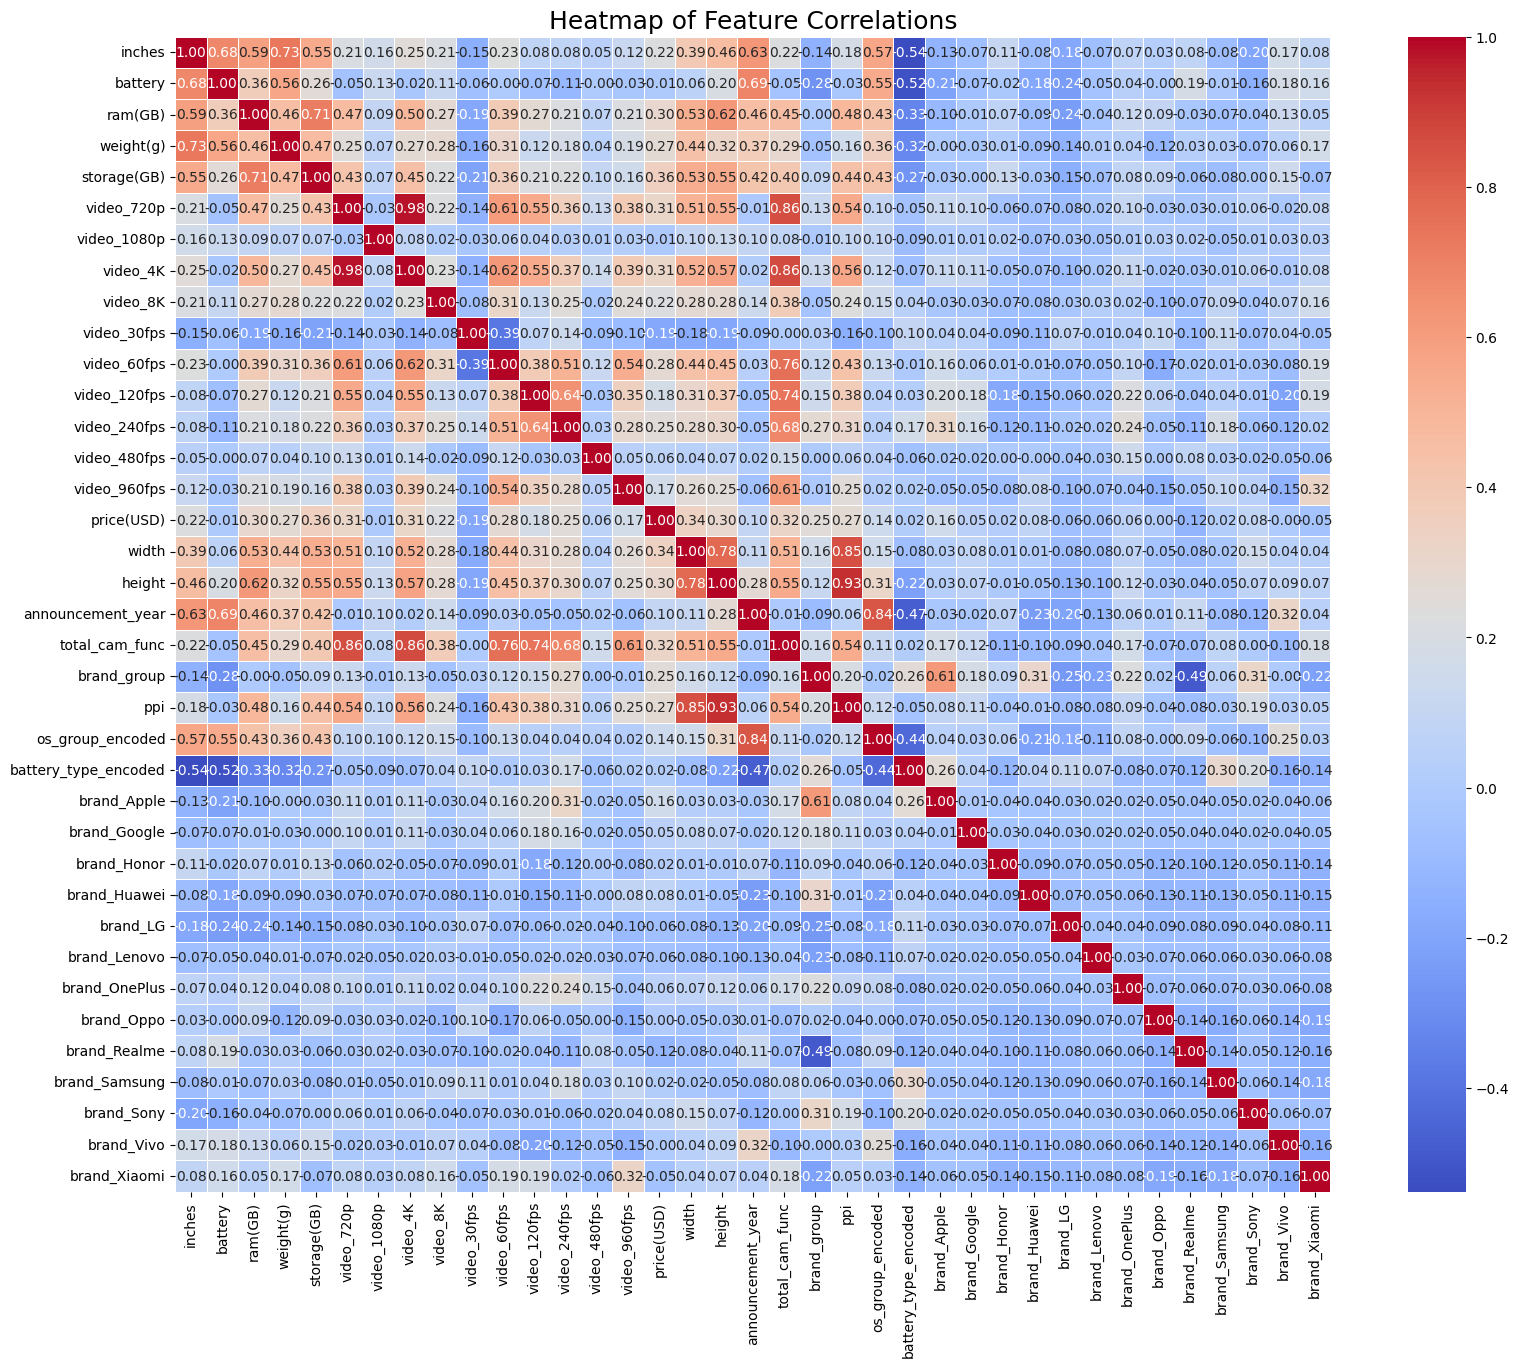

In [ ]:
corr = df_scaled.corr()
plt.figure(figsize=(20, 15))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Heatmap of Feature Correlations', fontsize=18)
plt.show()

In [ ]:
# Sắp xếp giảm dần tính tương quan với giá
corr = df_scaled.corr()['price(USD)'].sort_values(ascending=False)
corr

,price(USD)
price(USD),1.000000
storage(GB),0.355010
width,0.340797
total_cam_func,0.316641
video_4K,0.311706
video_720p,0.310560
ram(GB),0.296538
height,0.295540
video_60fps,0.278478
ppi,0.271723


In [ ]:
#normal dataset
df['log_ppi'] = np.log(df['ppi'])
df['log_price'] = np.log(df['price(USD)'])
df.drop(columns=[
    'announcement_year',
    'brand_Sony',
    'brand_Huawei',
    'video_480fps',
    'brand_OnePlus',
    'brand_Google',
    'brand_Honor',
    'battery_type_encoded',
    'brand_Samsung',
    'brand_Oppo',
    'brand_Vivo',
    'video_1080p',
    'battery',
    'brand_Xiaomi',
    'brand_Lenovo',
    'brand_LG',
    'brand_Realme',
    'video_30fps',
    'ppi',
    'price(USD)'
], inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1505 entries, 0 to 1511
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   inches            1505 non-null   float64
 1   ram(GB)           1505 non-null   int64  
 2   weight(g)         1505 non-null   float64
 3   storage(GB)       1505 non-null   int64  
 4   video_720p        1505 non-null   int64  
 5   video_4K          1505 non-null   int64  
 6   video_8K          1505 non-null   int64  
 7   video_60fps       1505 non-null   int64  
 8   video_120fps      1505 non-null   int64  
 9   video_240fps      1505 non-null   int64  
 10  video_960fps      1505 non-null   int64  
 11  width             1505 non-null   int64  
 12  height            1505 non-null   int64  
 13  total_cam_func    1505 non-null   int64  
 14  brand_group       1505 non-null   float64
 15  os_group_encoded  1505 non-null   int64  
 16  brand_Apple       1505 non-null   int64  
 17  

In [ ]:
#scaled dataset
df_scaled.drop(columns=[
    'announcement_year',
    'brand_Sony',
    'brand_Huawei',
    'video_480fps',
    'brand_OnePlus',
    'brand_Google',
    'brand_Honor',
    'battery_type_encoded',
    'brand_Samsung',
    'brand_Oppo',
    'brand_Vivo',
    'video_1080p',
    'battery',
    'brand_Xiaomi',
    'brand_Lenovo',
    'brand_LG',
    'brand_Realme',
    'video_30fps'
], inplace=True)
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1505 entries, 0 to 1504
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   inches            1505 non-null   float64
 1   ram(GB)           1505 non-null   float64
 2   weight(g)         1505 non-null   float64
 3   storage(GB)       1505 non-null   float64
 4   video_720p        1505 non-null   float64
 5   video_4K          1505 non-null   float64
 6   video_8K          1505 non-null   float64
 7   video_60fps       1505 non-null   float64
 8   video_120fps      1505 non-null   float64
 9   video_240fps      1505 non-null   float64
 10  video_960fps      1505 non-null   float64
 11  price(USD)        1505 non-null   float64
 12  width             1505 non-null   float64
 13  height            1505 non-null   float64
 14  total_cam_func    1505 non-null   float64
 15  brand_group       1505 non-null   float64
 16  ppi               1505 non-null   float64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
df_scaled.to_csv('/content/drive/MyDrive/Python for ML/Build Model/cleaned_all_phones_final.csv', index=False)
df.to_csv('/content/drive/MyDrive/Python for ML/Build Model/cleaned_all_phones_normal.csv', index=False)
x.to_csv('/content/drive/MyDrive/Python for ML/Build Model/price_final.csv', index=False)

Mounted at /content/drive
